# Verification notebook — microseismic time-reversal simulator

**GPGN 436/536 Final Project · Rory Switala**

This notebook verifies the **same simulation code that the web app runs** (the `microseismic` package in this repository). Nothing here re-implements the solver: every test calls `microseismic.solver.Propagator`, `forward`, `backpropagate` and `pick_events` directly.

The app solves the 2D acoustic wave equation with an absorbing sponge,

$$\frac{\partial^2 p}{\partial t^2} + 2\sigma(x,z)\frac{\partial p}{\partial t} = v(x,z)^2\left(\frac{\partial^2 p}{\partial x^2}+\frac{\partial^2 p}{\partial z^2}\right) + s(x,z,t),$$

discretized with 2nd-order centred differences in time and the 8th-order centred stencil in space (course notes `06_Hyperbolic_PDEs`, Eqs. 23–25):

$$p^{n+1}_{i,j} = \frac{2p^n_{i,j} - (1-\sigma\Delta t)\,p^{n-1}_{i,j} + C^2_{i,j}\left(\sum_{k=-4}^{4} c_k p^n_{i+k,j} + \sum_{k=-4}^{4} c_k p^n_{i,j+k}\right) + \Delta t^2 s^n_{i,j}}{1+\sigma\Delta t}, \qquad C_{i,j} = \frac{v_{i,j}\Delta t}{\Delta x}.$$

A point source is injected as $\Delta t^2 s^n/\Delta x^2$ at its node (a discrete delta function).

**Tests**

1. **Point source in a homogeneous medium** vs. the analytical 2D Green's function — waveform error, convergence with grid spacing and with time step.
2. **Plane-wave reflection at a velocity interface** vs. the analytical 1D solution — checks the heterogeneous (layered) part of the code that the app relies on.
3. **Time-reversal location of a single event** — checks forward modelling + back-propagation + picking together, and how location error changes with grid spacing.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time

from microseismic import Model, ricker, forward, backpropagate, pick_events
from microseismic.solver import Propagator, point_weights

plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
print("numpy", np.__version__)

numpy 2.5.3


## Test 1 — point source in a homogeneous medium

### Analytical solution

For $p_{tt} = v^2\nabla^2 p + F(t)\,\delta(x-x_s)\delta(z-z_s)$ with $p = p_t = 0$ at $t=0$ in an unbounded homogeneous 2D medium, the solution is the time convolution of the source function $F$ with the 2D Green's function

$$G(r,t) = \frac{H(vt-r)}{2\pi v\sqrt{v^2t^2-r^2}}, \qquad p(r,t) = \int_{r/v}^{t} F(t-\tau)\,G(r,\tau)\,d\tau .$$

The integrand is singular at $\tau = r/v$, but the substitution $\tau = (r/v)\cosh u$ removes the singularity exactly:

$$p(r,t) = \frac{1}{2\pi v^2}\int_0^{\cosh^{-1}(vt/r)} F\!\left(t-\frac{r}{v}\cosh u\right)du,$$

which is smooth and can be integrated accurately with the trapezoid rule. $F$ is the same delayed Ricker wavelet the app uses.

### Matching parameters

| Quantity | Value |
|---|---|
| Velocity | $v = 3000$ m/s (single layer) |
| Source | Ricker, $f = 30$ Hz, peak at $t = 1.5/f$, at the centre of an 800 m × 800 m model |
| Receivers | offsets $r$ = 60, 100, 140 m along +x |
| Initial conditions | $p = 0$, $p_t = 0$ (start from rest) |
| Boundary conditions | sponge + $p=0$ outside it; the model is large enough that no boundary energy returns within the 0.16 s window, so the numerical problem matches the unbounded analytical one |
| Courant number | $C = 0.4$ |

grid 161 x 161, dt = 0.667 ms, 241 steps, run time 0.1 s
points per minimum wavelength at 2.5 f: 8.0


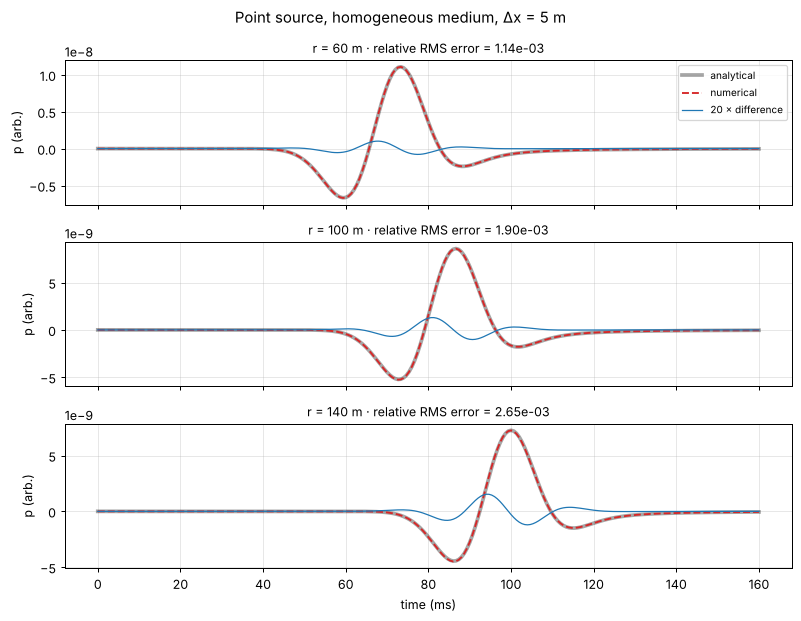

In [2]:
def analytic_point_source(r, t, v, f, n_quad=4000):
    # 2D Green's function convolved with the Ricker wavelet (substitution tau = r/v cosh u).
    p = np.zeros_like(t)
    for i, ti in enumerate(t):
        if v * ti <= r:
            continue
        u = np.linspace(0.0, np.arccosh(v * ti / r), n_quad)
        p[i] = np.trapezoid(ricker(ti - (r / v) * np.cosh(u), f), u) / (2 * np.pi * v**2)
    return p

V, F0 = 3000.0, 30.0
OFFSETS = np.array([60.0, 100.0, 140.0])

def homogeneous_model(dx, courant=0.4):
    return Model(width=800.0, height=800.0, z_top=0.0, dx=dx, courant=courant, frequency=F0,
                 duration=0.16, layers=(("homogeneous", 800.0, V),), pad=20)

def simulate_point_source(model):
    # Uses the app's Propagator (same stencil, sponge and source injection).
    src = point_weights([(400.0, 400.0)], model)
    rec = point_weights(np.column_stack((400.0 + OFFSETS, np.full(3, 400.0))), model)
    return Propagator(model).run(src, ricker(model.t, F0)[:, None], record=rec)

def relative_rms_error(numerical, exact):
    return np.sqrt(np.mean((numerical - exact) ** 2)) / np.max(np.abs(exact))

m = homogeneous_model(dx=5.0)
start = time.perf_counter()
data = simulate_point_source(m)
print(f"grid {m.nx} x {m.nz}, dt = {1e3*m.dt:.3f} ms, {m.nt} steps, run time {time.perf_counter()-start:.1f} s")
print(f"points per minimum wavelength at 2.5 f: {m.points_per_wavelength():.1f}")

fig, axes = plt.subplots(len(OFFSETS), 1, figsize=(9, 7), sharex=True)
for j, (r, ax) in enumerate(zip(OFFSETS, axes)):
    exact = analytic_point_source(r, m.t, V, F0)
    ax.plot(1e3 * m.t, exact, "k", lw=3, alpha=0.35, label="analytical")
    ax.plot(1e3 * m.t, data[:, j], "C3--", lw=1.5, label="numerical")
    ax.plot(1e3 * m.t, 20 * (data[:, j] - exact), "C0", lw=1, label="20 × difference")
    ax.set_ylabel("p (arb.)")
    ax.set_title(f"r = {r:.0f} m · relative RMS error = {relative_rms_error(data[:, j], exact):.2e}", fontsize=10)
axes[0].legend(loc="upper right", fontsize=8)
axes[-1].set_xlabel("time (ms)")
fig.suptitle("Point source, homogeneous medium, Δx = 5 m")
fig.tight_layout()

The numerical and analytical waveforms overlap, including the long 2D "tail" behind the main pulse that a 2D (line-source) Green's function has. The difference (magnified 20×) is largest just after the arrival and grows with offset — the signature of a small accumulated phase (dispersion) error.

### Convergence with grid spacing

Refining $\Delta x$ at a **fixed Courant number** also refines $\Delta t = C\Delta x / v$. The spatial stencil is 8th-order but the time stepping is only 2nd-order, so the total error should fall as $\Delta x^2$ (the time error dominates).

 dx (m)   dt (ms)   err r=60 m   err r=100 m   err r=140 m
 10.00    1.3333       4.44e-03       7.38e-03       1.03e-02
  5.00    0.6667       1.14e-03       1.90e-03       2.65e-03
  2.50    0.3333       2.88e-04       4.77e-04       6.68e-04
  1.25    0.1667       7.81e-05       1.29e-04       1.81e-04

observed convergence order (log-log slope): [1.95 1.95 1.95]


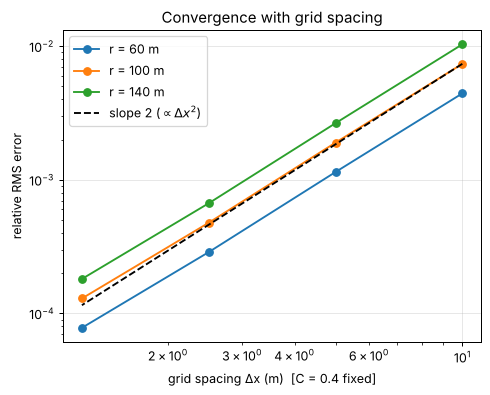

In [3]:
dxs = np.array([10.0, 5.0, 2.5, 1.25])
errors_dx = []
for dx in dxs:
    mm = homogeneous_model(dx)
    d = simulate_point_source(mm)
    errors_dx.append([relative_rms_error(d[:, j], analytic_point_source(r, mm.t, V, F0))
                      for j, r in enumerate(OFFSETS)])
errors_dx = np.array(errors_dx)

print(" dx (m)   dt (ms)   " + "   ".join(f"err r={r:.0f} m" for r in OFFSETS))
for dx, e in zip(dxs, errors_dx):
    print(f"{dx:6.2f}   {1e3*0.4*dx/V:7.4f}   " + "   ".join(f"{x:12.2e}" for x in e))
slopes = np.polyfit(np.log(dxs), np.log(errors_dx), 1)[0]
print("\nobserved convergence order (log-log slope):", np.round(slopes, 2))

fig, ax = plt.subplots(figsize=(6, 4.5))
for j, r in enumerate(OFFSETS):
    ax.loglog(dxs, errors_dx[:, j], "o-", label=f"r = {r:.0f} m")
ax.loglog(dxs, errors_dx[0, 1] * (dxs / dxs[0]) ** 2, "k--", label=r"slope 2 ($\propto\Delta x^2$)")
ax.set_xlabel("grid spacing Δx (m)  [C = 0.4 fixed]")
ax.set_ylabel("relative RMS error")
ax.set_title("Convergence with grid spacing")
ax.legend()

### Convergence with time step (fixed grid)

Keeping $\Delta x = 2.5$ m and lowering the Courant number isolates the time-discretization error.

C = 0.5   dt = 0.4167 ms   error (r = 100 m) = 7.44e-04
C = 0.4   dt = 0.3333 ms   error (r = 100 m) = 4.77e-04
C = 0.3   dt = 0.2500 ms   error (r = 100 m) = 2.70e-04
C = 0.2   dt = 0.1667 ms   error (r = 100 m) = 1.21e-04
C = 0.1   dt = 0.0833 ms   error (r = 100 m) = 3.16e-05
observed order in dt (largest four dt): 1.98


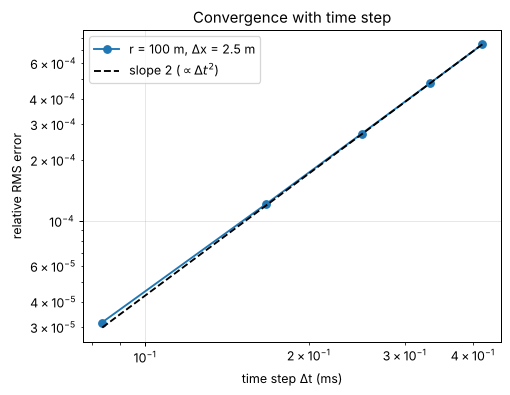

In [4]:
courants = np.array([0.5, 0.4, 0.3, 0.2, 0.1])
errors_dt, dts = [], []
for c in courants:
    mm = homogeneous_model(2.5, courant=c)
    d = simulate_point_source(mm)
    dts.append(mm.dt)
    errors_dt.append(relative_rms_error(d[:, 1], analytic_point_source(OFFSETS[1], mm.t, V, F0)))
dts, errors_dt = np.array(dts), np.array(errors_dt)
for c, dt, e in zip(courants, dts, errors_dt):
    print(f"C = {c:.1f}   dt = {1e3*dt:.4f} ms   error (r = 100 m) = {e:.2e}")
print("observed order in dt (largest four dt):", round(np.polyfit(np.log(dts[:4]), np.log(errors_dt[:4]), 1)[0], 2))

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.loglog(1e3 * dts, errors_dt, "o-", label="r = 100 m, Δx = 2.5 m")
ax.loglog(1e3 * dts, errors_dt[0] * (dts / dts[0]) ** 2, "k--", label=r"slope 2 ($\propto\Delta t^2$)")
ax.set_xlabel("time step Δt (ms)")
ax.set_ylabel("relative RMS error")
ax.set_title("Convergence with time step")
ax.legend()

**Interpretation.** With $C$ fixed, the error falls by about 4× for every halving of $\Delta x$ (slope ≈ 2), even though the spatial stencil is 8th-order: the 2nd-order leapfrog time stepping limits the overall accuracy. Lowering $\Delta t$ on a fixed grid confirms this — the error keeps falling as $\Delta t^2$ over the whole range tested, which shows that the spatial error of the 8th-order stencil is below about $3\times10^{-5}$ at $\Delta x = 2.5$ m. Practical consequence: for this scheme it is more effective to run near the stability limit with a fine grid than to shrink $\Delta t$ on a coarse grid. The app uses $\Delta x = 2.5$ m with ~10 points per minimum wavelength and $C = 0.45$; at that resolution the waveform error is well below 1 %.

The error also grows with offset because phase errors accumulate with propagation distance (numerical dispersion; notes Eq. 28).

The solver stores wavefields in single precision (`float32`) because that runs about twice as fast in the browser. Round-off (~10⁻⁶ relative) is far below the discretization error on the grids the app uses; it only starts to show as a slight flattening of the convergence curve at the finest grid (Δx = 1.25 m) and smallest time step.

## Test 2 — plane-wave reflection at a velocity interface

The app's velocity model is layered, so the heterogeneous part of the update ($C_{i,j}$ varying in space) must also be checked.

### Analytical solution

A **line of point sources** spanning the model at depth $z_s$ produces a plane wave. Each node source is given strength $F(t)\,\Delta x$; because the nodes are $\Delta x$ apart, the line then has source strength $F(t)\,\delta(z-z_s)$ per unit length, independent of the grid, and the problem becomes 1D. For $p_{tt} = v^2 p_{zz} + g(t)\delta(z-z_s)$ the solution is

$$p(z,t) = \frac{1}{2v}\int_0^{\,t-|z-z_s|/v} g(\tau)\,d\tau .$$

For this (constant-density) form of the wave equation, $p$ and $\partial p/\partial z$ are continuous across an interface, giving the normal-incidence reflection coefficient

$$R = \frac{v_2 - v_1}{v_2 + v_1}.$$

So a receiver above the source sees the direct wave and an interface reflection with amplitude $R$ times the direct wave:

$$p(t) = \frac{1}{2v_1}\Big[I(t - d_1/v_1) + R\,I(t - d_2/v_1)\Big],\qquad I(t) = \int_0^t F(\tau)\,d\tau .$$

### Matching parameters

| Quantity | Value |
|---|---|
| Layers | target shale $v_1 = 3300$ m/s over limestone $v_2 = 4800$ m/s (values from the app's default model), interface at $z = 800$ m |
| Source | horizontal line of Ricker sources (30 Hz) at $z_s = 650$ m across the full 1600 m width |
| Receiver | $x = 800$ m, $z = 600$ m → direct path $d_1 = 50$ m, reflected path $d_2 = 150 + 200 = 350$ m |
| ICs / BCs | start from rest; the model (1600 m × 1200 m) is large enough that energy from the top/bottom sponges and diffractions from the ends of the source line arrive after the 0.25 s window |

exact R = (v2 - v1)/(v2 + v1) = 0.1852
dx = 10.0 m: measured R = 0.1922  (error 3.80 %),  relative RMS waveform error = 2.60e-02
dx =  5.0 m: measured R = 0.1870  (error 0.97 %),  relative RMS waveform error = 1.26e-02
dx =  2.5 m: measured R = 0.1856  (error 0.23 %),  relative RMS waveform error = 6.23e-03


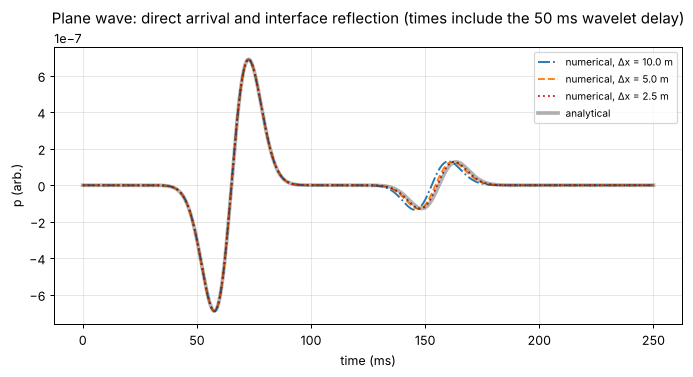

In [5]:
V1, V2, Z_INT = 3300.0, 4800.0, 800.0
R_exact = (V2 - V1) / (V2 + V1)

def interface_model(dx):
    return Model(width=1600.0, height=1200.0, z_top=0.0, dx=dx, courant=0.4, frequency=F0,
                 duration=0.25, layers=(("shale", Z_INT, V1), ("limestone", 400.0, V2)), pad=20)

def simulate_plane_wave(model):
    xs = model.x
    src = point_weights(np.column_stack((xs, np.full(len(xs), 650.0))), model)
    rec = point_weights([(800.0, 600.0)], model)
    # Each node source has strength F * dx -> line source of strength F per metre.
    forcing = np.repeat(ricker(model.t, F0)[:, None] * model.dx, len(xs), axis=1)
    return Propagator(model).run(src, forcing, record=rec)[:, 0]

def analytic_plane_wave(model):
    t = model.t
    I = np.concatenate(([0.0], np.cumsum(0.5 * (ricker(t[1:], F0) + ricker(t[:-1], F0)) * np.diff(t))))
    shift = lambda delay: np.interp(t - delay, t, I, left=0.0)
    return (shift(50.0 / V1) + R_exact * shift(350.0 / V1)) / (2 * V1)

fig, ax = plt.subplots(figsize=(9, 4))
print(f"exact R = (v2 - v1)/(v2 + v1) = {R_exact:.4f}")
for dx, style in ((10.0, "C0-."), (5.0, "C1--"), (2.5, "C3:")):
    mm = interface_model(dx)
    p = simulate_plane_wave(mm)
    exact = analytic_plane_wave(mm)
    direct = mm.t < 0.11                    # direct wave: arrives ~15 ms after the 50 ms wavelet delay
    reflected = mm.t >= 0.11                # reflection: ~106 ms + 50 ms
    R_num = np.ptp(p[reflected]) / np.ptp(p[direct])
    print(f"dx = {dx:>4} m: measured R = {R_num:.4f}  (error {100*abs(R_num - R_exact)/R_exact:.2f} %),"
          f"  relative RMS waveform error = {relative_rms_error(p, exact):.2e}")
    ax.plot(1e3 * mm.t, p, style, lw=1.5, label=f"numerical, Δx = {dx} m")
ax.plot(1e3 * mm.t, exact, "k", lw=3, alpha=0.3, label="analytical")
ax.set_xlabel("time (ms)"); ax.set_ylabel("p (arb.)")
ax.set_title("Plane wave: direct arrival and interface reflection (times include the 50 ms wavelet delay)")
ax.legend(fontsize=8)

**Interpretation.** The reflection arrives at the time predicted by the two-way path and with the amplitude predicted by $R = (v_2-v_1)/(v_2+v_1)$. The remaining error mainly comes from representing the sharp interface on the grid: the interface is a staircase of nodes, and its effective position is uncertain by up to one node, which slightly changes the reflection time and amplitude. The error falls as $\Delta x$ is refined. This test confirms that the spatially varying $C_{i,j}$ update — the part of the code the layered app model depends on — is implemented correctly.

## Test 3 — time-reversal location of a single event

The app's location step is: forward-model → record → re-inject the **time-reversed** traces at the receivers → find the space-time maximum of $p^2$. With unknown origin time $t_0$, a focus at reverse time $\tau$ gives $\hat t_0 = T - \tau - 1.5/f$.

In a homogeneous medium surrounded by receivers, the reverse wavefield should refocus at the true source location, to within the diffraction limit (≈ half a wavelength) and the grid spacing. This test runs `forward`, `backpropagate` and `pick_events` — exactly the functions the app calls — with the source deliberately placed **off** the grid nodes.

dominant wavelength = 100 m (half-wavelength resolution ~ 50 m)
 dx (m)   location error (m)   origin-time error (ms)
  10.0                  2.1                    -1.33
   5.0                  2.1                    -0.00
   2.5                  1.4                    -0.00


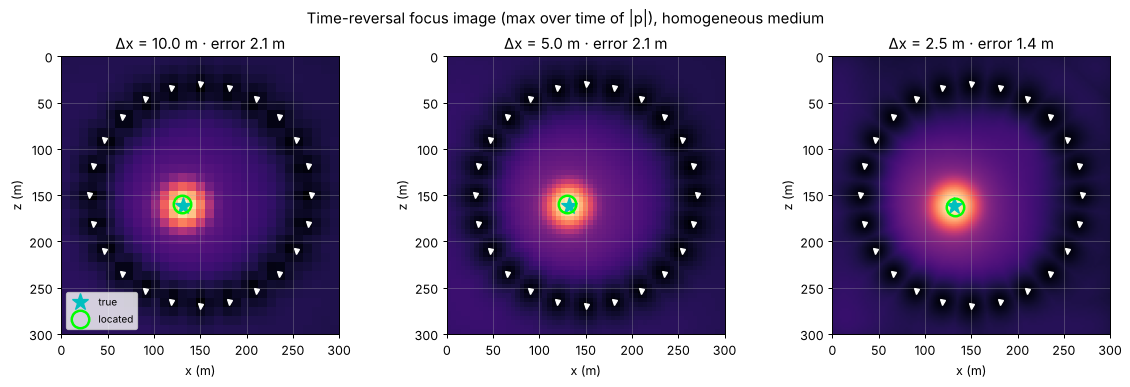

In [6]:
true_x, true_z, true_t0 = 131.7, 161.3, 0.010
events = dict(x=np.array([true_x]), z=np.array([true_z]), t0=np.array([true_t0]), amplitude=np.array([1.0]))
ang = np.linspace(0, 2 * np.pi, 24, endpoint=False)
ring = np.column_stack((150 + 120 * np.cos(ang), 150 + 120 * np.sin(ang)))

rows = []
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, dx in zip(axes, (10.0, 5.0, 2.5)):
    mm = Model(width=300.0, height=300.0, z_top=0.0, dx=dx, courant=0.4, frequency=F0, duration=0.25,
               layers=(("homogeneous", 300.0, V),), pad=20)
    fwd = forward(mm, events, ring)
    back = backpropagate(mm, fwd["data"], ring)
    pk = pick_events(mm, back, ring, max_events=1, mute_radius=30.0)
    err = np.hypot(pk["x"][0] - true_x, pk["z"][0] - true_z)
    rows.append((dx, err, 1e3 * (pk["t0"][0] - true_t0)))
    img = np.sqrt(pk["image_muted"]); img /= img.max()
    ax.imshow(img, extent=[0, mm.width, mm.z[-1], mm.z[0]], cmap="magma")
    ax.plot(ring[:, 0], ring[:, 1], "wv", ms=4)
    ax.plot(true_x, true_z, "c*", ms=14, label="true")
    ax.plot(pk["x"], pk["z"], "o", mfc="none", mec="lime", ms=14, mew=2, label="located")
    ax.set_title(f"Δx = {dx} m · error {err:.1f} m")
    ax.set_xlabel("x (m)"); ax.set_ylabel("z (m)")
axes[0].legend(loc="lower left", fontsize=8)
fig.suptitle("Time-reversal focus image (max over time of |p|), homogeneous medium")
fig.tight_layout()

lam = V / F0
print(f"dominant wavelength = {lam:.0f} m (half-wavelength resolution ~ {lam/2:.0f} m)")
print(" dx (m)   location error (m)   origin-time error (ms)")
for dx, e, dt0 in rows:
    print(f"{dx:6.1f}   {e:18.1f}   {dt0:22.2f}")

**Interpretation.** For all three grids the image refocuses at the true (off-grid) source, and the origin time is recovered to within a fraction of the 33 ms wavelet period. The location error is a few metres — set mostly by the grid spacing and by the picking (the image is sampled on the grid), far below the ~50 m half-wavelength width of the focal spot. Location error does not converge to zero like the waveform error, because the focus width is limited by diffraction (the wavelength), not by the numerical method.

## Limitations

* **2D acoustic physics.** The model is a 2D vertical section: sources are effectively *line* sources (2D Green's function, with its tail), there are no S-waves, and no source mechanism (real microseismic events are mostly shear failures with S-waves stronger than P). Out-of-plane distance from the monitoring well cannot be represented.
* **Sponge boundary.** The quadratic sponge reduces but does not eliminate edge reflections. The tests above avoid them by using large models; in the app a ~75 m sponge surrounds the model.
* **Time-step–limited accuracy.** Overall convergence is 2nd order, dominated by the leapfrog time step (Test 1).
* **Interface staircasing.** Layer boundaries are represented node-by-node (Test 2).
* **Imaging resolution.** Time-reversal resolution is about half a wavelength (~35 m for 50 Hz in the 3300 m/s target shale in the app); events closer than that at similar origin times merge. One-sided receiver arrays (a single monitoring well) smear the focus along the direction away from the array, and a single vertical well cannot tell which side of the well an event is on (mirror ambiguity), because the layered model is symmetric about the well.